## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Andrew Du

**Date:** October 13, 2026

### Q1. K-means clustering simulation

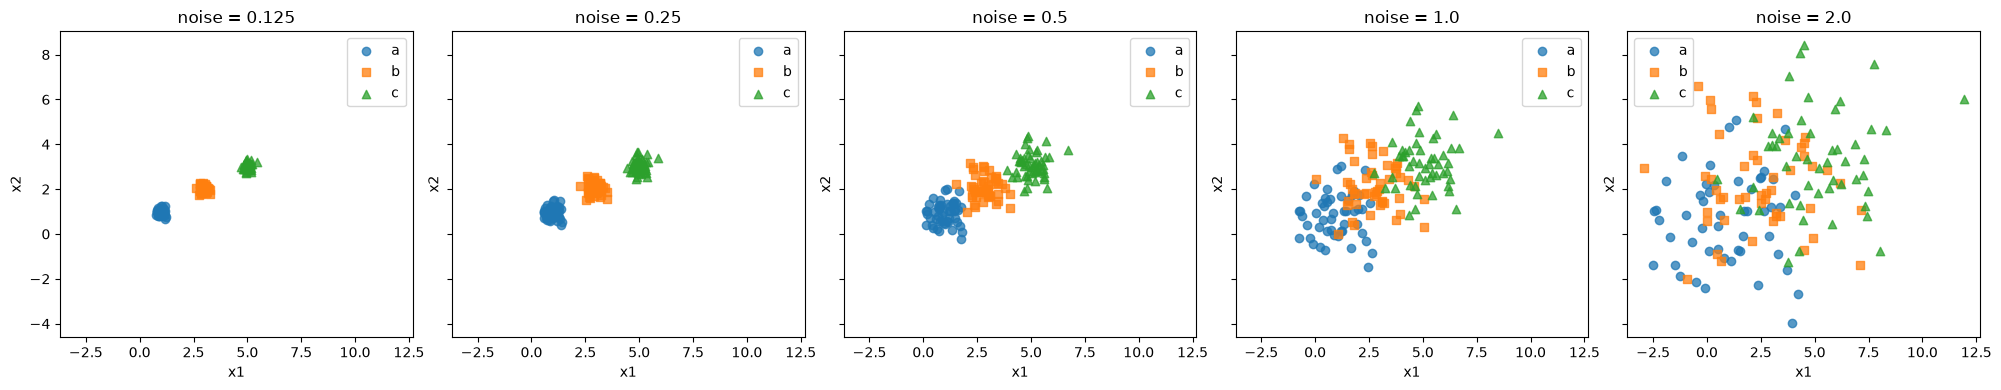

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Q1.1: create the five simulated datasets exactly as directed.
def createData(noise, N=50):
    np.random.seed(100)
    X1 = np.array([np.random.normal(1, noise, N), np.random.normal(1, noise, N)])
    X2 = np.array([np.random.normal(3, noise, N), np.random.normal(2, noise, N)])
    X3 = np.array([np.random.normal(5, noise, N), np.random.normal(3, noise, N)])

    gdf1 = pd.DataFrame({'x1': X1[0, :], 'x2': X1[1, :], 'group': 'a'})
    gdf2 = pd.DataFrame({'x1': X2[0, :], 'x2': X2[1, :], 'group': 'b'})
    gdf3 = pd.DataFrame({'x1': X3[0, :], 'x2': X3[1, :], 'group': 'c'})
    return pd.concat([gdf1, gdf2, gdf3], axis=0, ignore_index=True)

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

datasets = {
    'noise = 0.125': df0_125,
    'noise = 0.25': df0_25,
    'noise = 0.5': df0_5,
    'noise = 1.0': df1_0,
    'noise = 2.0': df2_0,
}

# Q1.2: scatterplots by true group.
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True, sharey=True)
markers = {'a': 'o', 'b': 's', 'c': '^'}
for ax, (name, df) in zip(axes, datasets.items()):
    for group, group_df in df.groupby('group'):
        ax.scatter(group_df['x1'], group_df['x2'], label=group, alpha=0.75, marker=markers[group])
    ax.set_title(name)
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.legend()
plt.tight_layout()
plt.show()

**Q1.2 answer.** At noise 0.125 and 0.25, the three groups are very visually distinct. At 0.5 they are still recognizable but begin to overlap. At noise 1.0 the overlap is substantial, and at 2.0 the groups are heavily mixed. Increasing the standard deviation spreads observations farther from their true centers, so the visual separation between clusters becomes weaker.

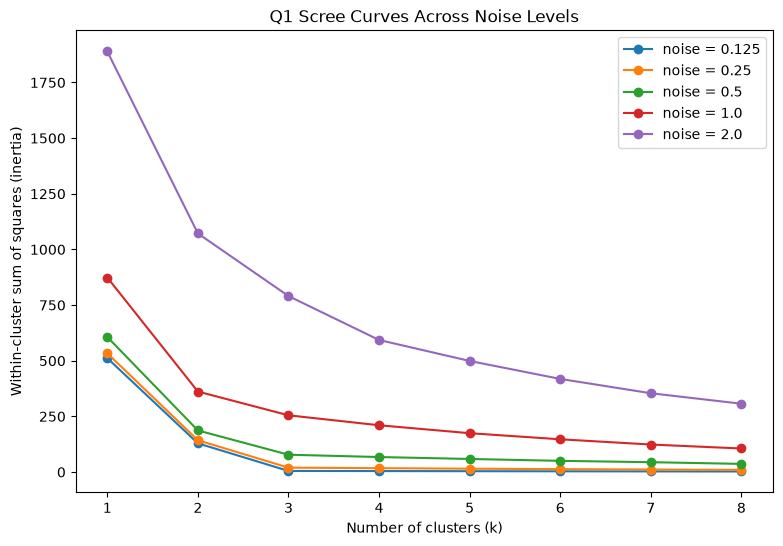

,noise = 0.125,noise = 0.25,noise = 0.5,noise = 1.0,noise = 2.0
k,,,,,
1,511.611829,533.252099,606.617962,873.690983,1889.202201
2,128.886790,142.720519,186.781235,361.588090,1071.812278
3,4.913219,19.652874,77.777015,254.882147,790.479064
4,4.333632,17.343286,67.364230,210.158530,593.190269
5,3.773758,15.060118,58.724471,174.455247,498.984278
6,3.263428,12.934612,50.241193,147.089886,418.292778
7,2.784334,11.256016,44.240675,123.563874,354.017620
8,2.409716,9.664537,36.627382,105.744158,306.862251


In [9]:
# Q1.3: scree curves for k = 1,...,8 on a common canvas.
k_values = range(1, 9)
q1_inertias = {}

plt.figure(figsize=(9, 6))
for name, df in datasets.items():
    X = df[['x1', 'x2']]
    inertias = []
    for k in k_values:
        model = KMeans(n_clusters=k, random_state=42, n_init=20)
        model.fit(X)
        inertias.append(model.inertia_)
    q1_inertias[name] = inertias
    plt.plot(list(k_values), inertias, marker='o', label=name)

plt.xlabel('Number of clusters (k)')
plt.ylabel('Within-cluster sum of squares (inertia)')
plt.title('Q1 Scree Curves Across Noise Levels')
plt.xticks(list(k_values))
plt.legend()
plt.show()

pd.DataFrame(q1_inertias, index=list(k_values)).rename_axis('k')

**Q1.3 answer.** With low noise, the scree curve drops sharply through about $k=3$ and then becomes almost flat, so the elbow at 3 is easy to identify. As noise increases, the total within-cluster variation increases and the curve becomes smoother. By noise 1.0 and especially 2.0, there is no single dramatic bend, so choosing $k$ from the elbow alone becomes much less definitive.

**Q1.4 answer.** The elbow is the point where adding another cluster stops buying a large reduction in within-cluster sum of squares. In the low-noise simulations, moving from one to two and then three clusters greatly reduces inertia because those clusters correspond to the three generating centers. Once $k=3$, additional centers mostly split already compact groups, so the improvement is small. With high noise the true groups overlap, so even the correct number of generating groups does not create as sharp a change in inertia.

### Q2. SIPRI military expenditure data

In [10]:
# Q2.1: load, filter to 2020, and remove rows with missing values.
sipri = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')

sipri_2020 = sipri.loc[sipri['Year'] == 2020].copy()
sipri_2020 = sipri_2020.dropna().reset_index(drop=True)

print('Rows after filtering and dropna:', len(sipri_2020))
print(sipri_2020.dtypes)
sipri_2020.head()

Rows after filtering and dropna: 148
index                               int64
Year                                int64
Country                               str
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
0,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
1,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
2,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
3,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
4,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


**Q2.1 answer.** After filtering to 2020 and dropping missing rows, there are 148 countries. The four measures used for clustering are already numeric, so I do not need additional recoding. The `Country` column stays as an identifier, and I do not include the old index or year in the clustering features.

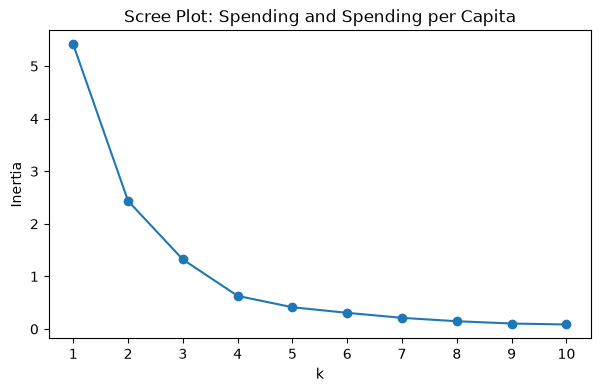

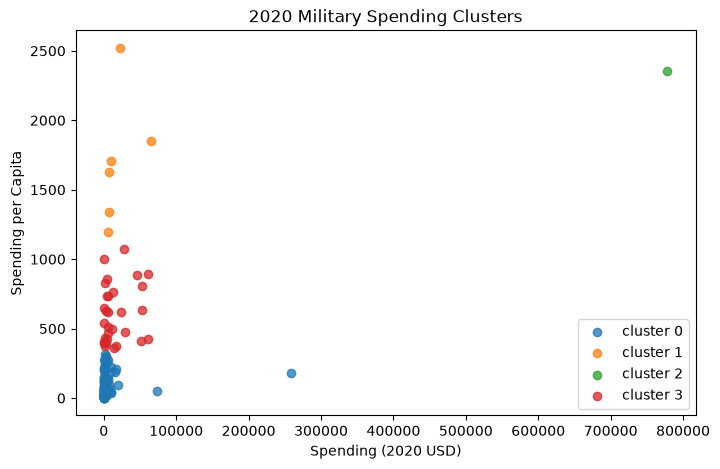

Spending (2020 USD)                                              \
                            count           mean           std            min   
spend_cluster                                                                   
0                           111.0    4859.185065  25405.739131       8.622460   
1                             6.0   19443.362047  22861.507114    6095.708713   
2                             1.0  778397.200000           NaN  778397.200000   
3                            30.0   17077.591354  20583.053357     405.790494   

                                                                           \
                         25%            50%            75%            max   
spend_cluster                                                               
0                 130.010211     382.464677    2297.032353  257973.429834   
1                7023.251766    8624.225729   18857.070183   64558.400000   
2              778397.200000  778397.200000  778397.200000  778397.200000   
3                2294.039665    5857.060906   26296.001003   61712.537169   

              Spending per Capita                                        \
                            count         mean         std          min   
spend_cluster                                                             
0                           111.0    80.061470   83.501824     0.580129   
1                             6.0  1706.721916  466.375705  1193.598730   
2                             1.0  2351.631858         NaN  2351.631858   
3                            30.0   607.478618  206.928757   362.467076   

                                                                   
                       25%          50%          75%          max  
spend_cluster                                                      
0                14.880549    47.056944   125.387558   314.201312  
1              1412.083201  1665.447478  1817.219993  2520.398541  
2              2351.631858  2351.631858  2351.631858  2351.631858  
3               422.208252   579.004604   757.328513  1070.623322

Cluster sizes:
spend_cluster
0    111
1      6
2      1
3     30
Name: count, dtype: int64

United States:


,Country,Spending (2020 USD),Spending per Capita,spend_cluster
144,United States of America,778397.2,2351.631858,2


In [ ]:
# Helper used for the required max-min normalization.
def minmax(series):
    return (series - series.min()) / (series.max() - series.min())

# Q2.2: Spending and Spending per Capita.
spend_cols = ['Spending (2020 USD)', 'Spending per Capita']
spend_norm = sipri_2020[spend_cols].apply(minmax)

spend_inertia = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    km.fit(spend_norm)
    spend_inertia.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), spend_inertia, marker='o')
plt.xticks(range(1, 11))
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('Scree Plot: Spending and Spending per Capita')
plt.show()

# The elbow remains pronounced through roughly k=4.
k_spend = 4
spend_model = KMeans(n_clusters=k_spend, random_state=42, n_init=20)
sipri_2020['spend_cluster'] = spend_model.fit_predict(spend_norm)

plt.figure(figsize=(8, 5))
for cluster, part in sipri_2020.groupby('spend_cluster'):
    plt.scatter(part['Spending (2020 USD)'], part['Spending per Capita'], label=f'cluster {cluster}', alpha=0.75)
plt.xlabel('Spending (2020 USD)')
plt.ylabel('Spending per Capita')
plt.title('2020 Military Spending Clusters')
plt.legend()
plt.show()

display(sipri_2020.groupby('spend_cluster')[spend_cols].describe())
print('Cluster sizes:')
print(sipri_2020['spend_cluster'].value_counts().sort_index())
print()
print('United States:')
display(sipri_2020.loc[sipri_2020['Country'] == 'United States of America', ['Country'] + spend_cols + ['spend_cluster']])

**Q2.2 answer.** The data are very right-skewed. Most countries fall into a large low-spending cluster, while several richer or larger military powers form higher-spending or higher-per-capita groups. The United States is the most extreme observation in total spending and is separated into its own cluster with this $k=4$ solution. A different cluster contains countries such as Saudi Arabia, Israel, Singapore, Norway, Kuwait, and Oman that are notable for high spending per capita. This shows why normalization matters: otherwise total spending would dominate the distance calculation.

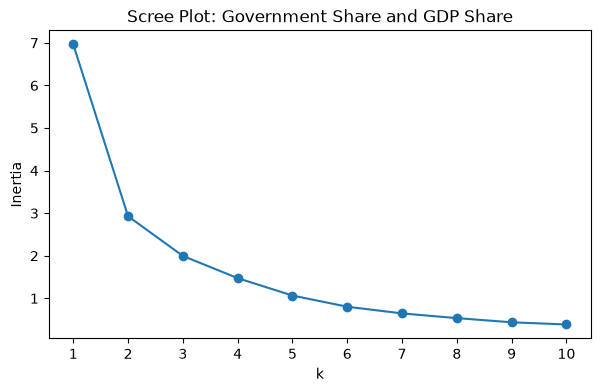

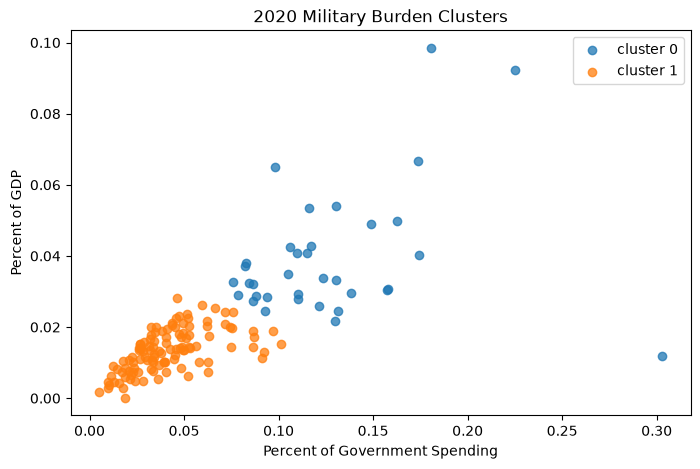

Percent of Government Spending                                \
                                       count      mean       std       min   
share_cluster                                                                
0                                       35.0  0.126456  0.046209  0.076005   
1                                      113.0  0.041394  0.020681  0.004896   

                                                      Percent of GDP  \
                    25%       50%       75%       max          count   
share_cluster                                                          
0              0.093093  0.116052  0.143584  0.303027           35.0   
1              0.026783  0.038486  0.051496  0.101501          113.0   

                                                                           \
                   mean       std       min       25%       50%       75%   
share_cluster                                                               
0              0.039433  0.018179  0.011742  0.028962  0.033281  0.042722   
1              0.013481  0.005966  0.000054  0.009147  0.013631  0.017830   

                         
                    max  
share_cluster            
0              0.098470  
1              0.028132

Cluster sizes:
share_cluster
0     35
1    113
Name: count, dtype: int64

United States:


,Country,Percent of Government Spending,Percent of GDP,share_cluster
144,United States of America,0.081976,0.037179,0


In [12]:
# Q2.3: Percent of Government Spending and Percent of GDP.
share_cols = ['Percent of Government Spending', 'Percent of GDP']
share_norm = sipri_2020[share_cols].apply(minmax)

share_inertia = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    km.fit(share_norm)
    share_inertia.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), share_inertia, marker='o')
plt.xticks(range(1, 11))
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('Scree Plot: Government Share and GDP Share')
plt.show()

# Here the strongest bend occurs very early, around k=2.
k_share = 2
share_model = KMeans(n_clusters=k_share, random_state=42, n_init=20)
sipri_2020['share_cluster'] = share_model.fit_predict(share_norm)

plt.figure(figsize=(8, 5))
for cluster, part in sipri_2020.groupby('share_cluster'):
    plt.scatter(part['Percent of Government Spending'], part['Percent of GDP'], label=f'cluster {cluster}', alpha=0.75)
plt.xlabel('Percent of Government Spending')
plt.ylabel('Percent of GDP')
plt.title('2020 Military Burden Clusters')
plt.legend()
plt.show()

display(sipri_2020.groupby('share_cluster')[share_cols].describe())
print('Cluster sizes:')
print(sipri_2020['share_cluster'].value_counts().sort_index())
print()
print('United States:')
display(sipri_2020.loc[sipri_2020['Country'] == 'United States of America', ['Country'] + share_cols + ['share_cluster']])

**Q2.3 answer.** These clusters are different from part 2 because they describe military burden or priority rather than the absolute scale of the military budget. The higher-share cluster has countries that devote a relatively large fraction of GDP and/or government spending to the military. The United States falls in that higher-burden group, but it is not uniquely separated the way it is by total spending. Countries can therefore be small in dollars yet still have a high military burden, while some very large economies can spend many dollars without having an unusually high percentage.

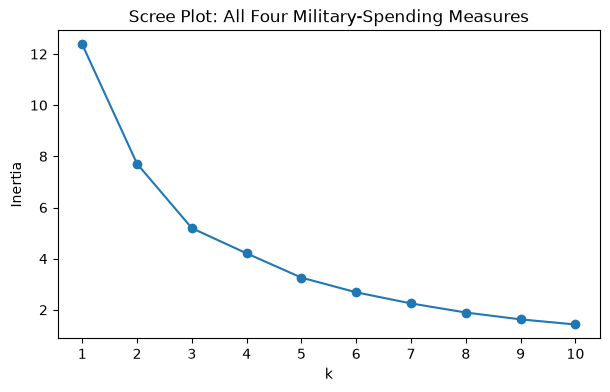

Cluster sizes:
all_cluster
0     31
1      6
2    111
Name: count, dtype: int64

Cluster means on original variables:


,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
all_cluster,,,,
0,8786.086602,212.689100,0.122985,0.033492
1,147964.582042,1875.150751,0.135351,0.062634
2,7086.472777,196.926833,0.040350,0.013419



United States:


,Country,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP,all_cluster
144,United States of America,778397.2,2351.631858,0.081976,0.037179,1


Cluster 0 sample/highest-spending members:
['India', 'Russia', 'Korea, South', 'Iran', 'Taiwan', 'Pakistan', 'Algeria', 'Colombia', 'Ukraine', 'Iraq', 'Morocco', 'Myanmar']
Cluster 1 sample/highest-spending members:
['United States of America', 'Saudi Arabia', 'Israel', 'Singapore', 'Kuwait', 'Oman']
Cluster 2 sample/highest-spending members:
['China', 'United Kingdom', 'Germany', 'France', 'Japan', 'Italy', 'Australia', 'Canada', 'Brazil', 'Turkey', 'Spain', 'Poland']


In [13]:
# Q2.4: all four numeric variables together.
all_cols = [
    'Spending (2020 USD)',
    'Spending per Capita',
    'Percent of Government Spending',
    'Percent of GDP'
]
all_norm = sipri_2020[all_cols].apply(minmax)

all_inertia = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    km.fit(all_norm)
    all_inertia.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), all_inertia, marker='o')
plt.xticks(range(1, 11))
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('Scree Plot: All Four Military-Spending Measures')
plt.show()

k_all = 3
all_model = KMeans(n_clusters=k_all, random_state=42, n_init=20)
sipri_2020['all_cluster'] = all_model.fit_predict(all_norm)

print('Cluster sizes:')
print(sipri_2020['all_cluster'].value_counts().sort_index())
print()
print('Cluster means on original variables:')
display(sipri_2020.groupby('all_cluster')[all_cols].mean())
print()
print('United States:')
display(sipri_2020.loc[sipri_2020['Country'] == 'United States of America', ['Country'] + all_cols + ['all_cluster']])

for cluster in sorted(sipri_2020['all_cluster'].unique()):
    members = sipri_2020.loc[sipri_2020['all_cluster'] == cluster].sort_values('Spending (2020 USD)', ascending=False)
    print(f'Cluster {cluster} sample/highest-spending members:')
    print(members['Country'].head(12).tolist())

**Q2.4 answer.** Using all four normalized measures combines scale with burden. With $k=3$, one group contains most lower-burden countries, another contains countries with relatively high military shares, and a small high-intensity/high-per-capita group contains the most extreme cases. The United States moves from being a one-country spending cluster to a small cluster with countries such as Saudi Arabia, Israel, Singapore, Kuwait, and Oman because the percentage variables now matter too. This result is a compromise between the absolute-spending structure in part 2 and the burden structure in part 3.

**Q2.5 answer.** Yes. K-means is useful here as an exploratory summary because it separates countries with very different military-spending profiles and makes the outliers easy to identify. It also shows that “high military spending” can mean different things: high total dollars, high per-capita spending, or a high share of national resources. The clusters should not be treated as natural or permanent categories, however. The chosen $k$ is subjective, K-means is sensitive to scaling and outliers, and countries near a boundary can change groups when different variables are used.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.


- **Phase 1 commit SHA ID:** `f6f70bcf56e2be6841baa116e0f8c3c5d8b94230`
- **AI tool and model used:** ChatGPT — GPT-5.6 Sol

### *Prompts used

1. Audit my Phase 1 A04 clustering solution against the rubric. Identify concrete improvements for Q1 and Q2 without changing the frozen Phase 1 cells. Check the simulation plots, scree-plot reasoning, max-min normalization, K-means choices, U.S. interpretation, and comparisons across feature sets.

2. For each suggested improvement, explain how I can verify it independently. Then provide a revised Phase 2 solution in full that preserves the assignment requirements and makes the analysis more reproducible and easier to check.

### *AI-proposed changes


**Q1 improvements**

1. Use fixed `random_state` and `n_init` values everywhere so the K-means results are reproducible.

2. Put all five Q1 scree curves on the same axes and explicitly connect increasing noise to a weaker elbow at the true generating value $k=3$.

**Q2 improvements**

3. Add explicit data checks for Q2: verify the 148 complete 2020 rows, confirm the four clustering variables are numeric, and confirm there are no missing values after cleaning.

4. Apply max-min normalization only to the variables being clustered, while keeping the original variables available for readable plots and summary tables.

5. State and justify the chosen elbow values rather than silently selecting them: use $k=4$ for spending/per-capita, $k=2$ for the two percentage variables, and $k=3$ for all four variables.

6. Print cluster sizes, conditional descriptive statistics, and the United States row for each relevant analysis so the written interpretation can be checked directly against output.

7. Make the comparisons across parts more explicit: absolute scale, military burden, and the combined four-variable solution answer different questions.

8. Document limitations: elbow selection is subjective, K-means labels are arbitrary, outliers can strongly affect Euclidean-distance clusters, and min-max scaling depends on the observed range.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Reproducibility is necessary. I reran the notebook with `random_state=42` and `n_init=20` and checked that the same inertias and memberships were returned. |
| 2 | Accept | A common Q1 canvas makes the change in the elbow easier to compare without confusing changes in axis scale. I verified that low-noise curves have a strong bend at 3 while high-noise curves are smoother. |
| 3 | Accept | The assignment says the cleaned data should contain 148 countries. I added assertions for row count, numeric types, and missing values. |
| 4 | Accept | K-means uses Euclidean distance, so scaling is required when units differ. I verified each normalized clustering column ranges from 0 to 1. |
| 5 | Modify | The elbow is not mathematically unique, so I kept these as defensible choices rather than calling them objectively correct. I checked the inertia tables and plots before selecting each value. |
| 6 | Accept | The extra printed output lets me check the U.S. and cluster descriptions directly instead of relying only on a graph. |
| 7 | Accept | This directly addresses the rubric's comparison questions and prevents treating all three clusterings as if they measure the same concept. |
| 8 | Accept | These are real limitations of K-means and of this data. I kept them in the final interpretation so the conclusions are not overstated. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

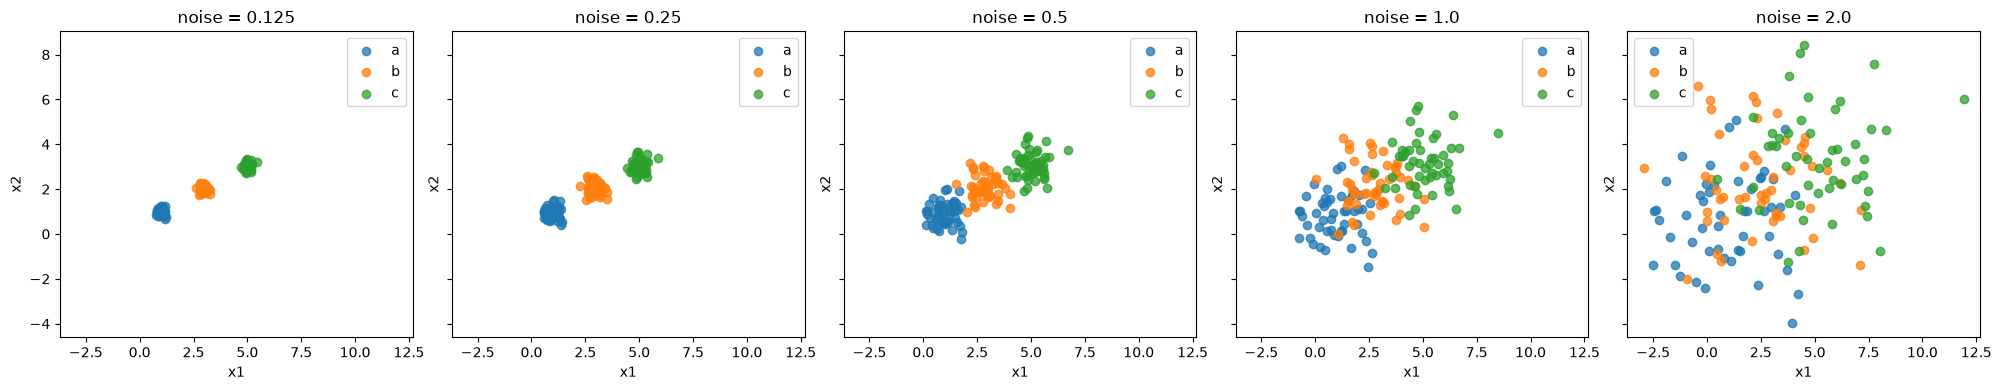

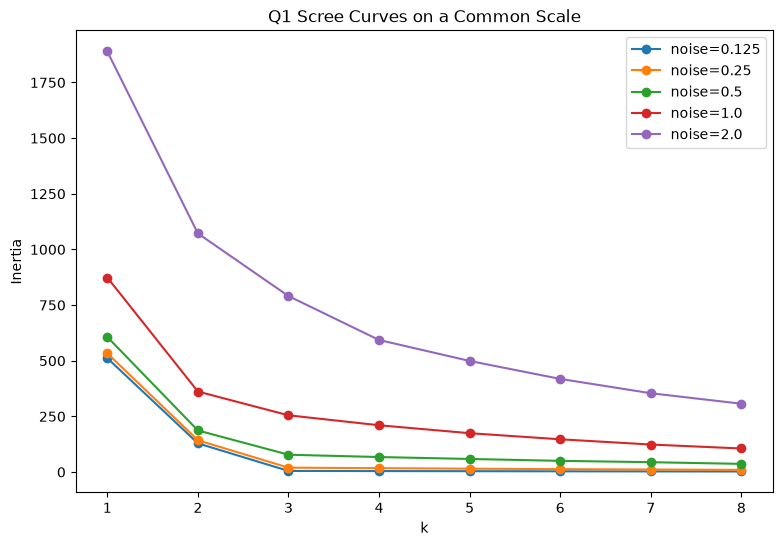

,noise=0.125,noise=0.25,noise=0.5,noise=1.0,noise=2.0
1,511.61,533.25,606.62,873.69,1889.20
2,128.89,142.72,186.78,361.59,1071.81
3,4.91,19.65,77.78,254.88,790.48
4,4.33,17.34,67.36,210.16,593.19
5,3.77,15.06,58.72,174.46,498.98
6,3.26,12.93,50.24,147.09,418.29
7,2.78,11.26,44.24,123.56,354.02
8,2.41,9.66,36.63,105.74,306.86


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

RANDOM_STATE = 42
N_INIT = 20

def createData(noise, N=50):
    np.random.seed(100)
    X1 = np.array([np.random.normal(1, noise, N), np.random.normal(1, noise, N)])
    X2 = np.array([np.random.normal(3, noise, N), np.random.normal(2, noise, N)])
    X3 = np.array([np.random.normal(5, noise, N), np.random.normal(3, noise, N)])

    return pd.concat([
        pd.DataFrame({'x1': X1[0], 'x2': X1[1], 'group': 'a'}),
        pd.DataFrame({'x1': X2[0], 'x2': X2[1], 'group': 'b'}),
        pd.DataFrame({'x1': X3[0], 'x2': X3[1], 'group': 'c'})
    ], ignore_index=True)

datasets = {
    0.125: createData(0.125),
    0.25: createData(0.25),
    0.5: createData(0.5),
    1.0: createData(1.0),
    2.0: createData(2.0),
}

# Scatterplots with shared limits
fig, axes = plt.subplots(
    1, 5,
    figsize=(20, 4),
    sharex=True,
    sharey=True
)

for ax, (noise, df) in zip(axes, datasets.items()):
    for g, part in df.groupby('group'):
        ax.scatter(
            part['x1'],
            part['x2'],
            alpha=0.75,
            label=g
        )

    ax.set_title(f'noise = {noise}')
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.legend()

plt.tight_layout()
plt.show()

# Scree curves on one set of axes
k_values = list(range(1, 9))
q1_inertia = pd.DataFrame(index=k_values)

for noise, df in datasets.items():
    X = df[['x1', 'x2']]

    q1_inertia[f'noise={noise}'] = [
        KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=N_INIT
        ).fit(X).inertia_
        for k in k_values
    ]

ax = q1_inertia.plot(
    marker='o',
    figsize=(9, 6)
)

ax.set_xlabel('k')
ax.set_ylabel('Inertia')
ax.set_title('Q1 Scree Curves on a Common Scale')
ax.set_xticks(k_values)

plt.show()

display(q1_inertia.round(2))



**Revised Q1 interpretation.**

The scatterplots show a monotonic loss of visual separation as noise increases. At 0.125 and 0.25 the true groups are compact; at 0.5 their edges start to overlap; at 1.0 and 2.0 the generating groups overlap enough that visual assignment becomes uncertain.

The scree results tell the same story. At low noise, inertia collapses when moving to $k=3$ and then changes only slightly, so the true three-center structure produces an obvious elbow.

At higher noise, within-group variance is large even when $k=3$, so additional centroids continue to reduce inertia more gradually and the elbow becomes less decisive.

The elbow therefore represents diminishing returns: choose the smallest $k$ after which extra centroids mostly subdivide existing structure instead of capturing a major new grouping.

Q2.1 — DATA VALIDATION
2020 complete observations: 148

Feature types:
Spending (2020 USD)               float64
Spending per Capita               float64
Percent of Government Spending    float64
Percent of GDP                    float64
dtype: object

First five countries:


,Country,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
0,Afghanistan,279.576955,7.181899,0.049728,0.013589
1,Albania,187.433234,65.126211,0.037952,0.012583
2,Algeria,9708.277440,221.392384,0.173924,0.066600
3,Angola,993.594405,30.231680,0.074624,0.014442
4,Argentina,2830.929705,62.636731,0.017268,0.007269



Data validation passed.


Q2.2 — SPENDING AND SPENDING PER CAPITA

Normalized feature ranges:


,Spending (2020 USD),Spending per Capita
min,0.0,0.0
max,1.0,1.0


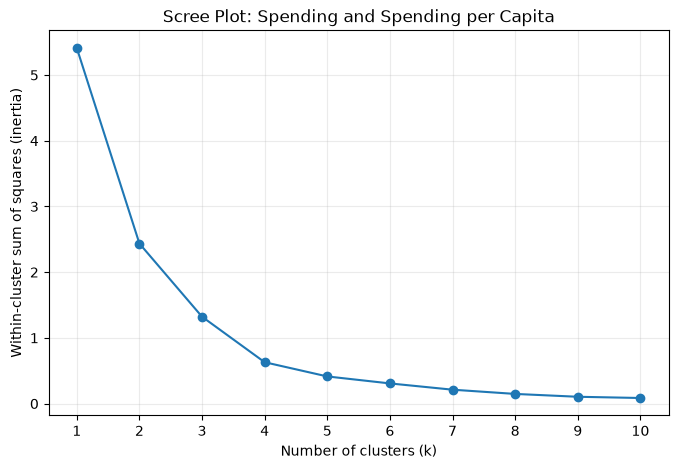

,k,Inertia
0,1,5.4114
1,2,2.4353
2,3,1.3218
3,4,0.6294
4,5,0.4131
5,6,0.3070
6,7,0.2116
7,8,0.1471
8,9,0.1038
9,10,0.0852



2020 Military Spending Clusters

Chosen k: 4

Cluster sizes:


,Number of countries
spend_cluster,
0,111
1,6
2,1
3,30


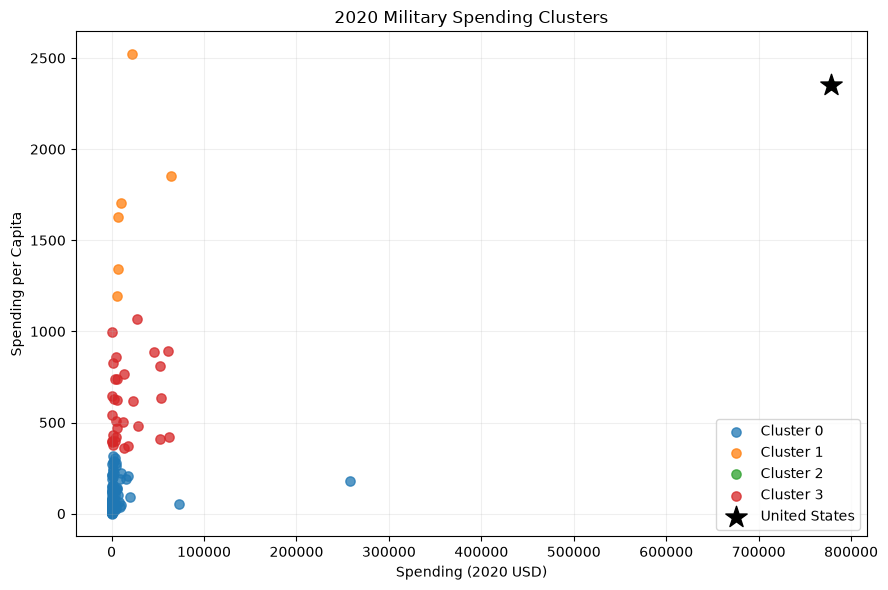


Descriptive statistics by cluster:


Spending (2020 USD)                                              \
                            count           mean           std            min   
spend_cluster                                                                   
0                           111.0    4859.185065  25405.739131       8.622460   
1                             6.0   19443.362047  22861.507114    6095.708713   
2                             1.0  778397.200000           NaN  778397.200000   
3                            30.0   17077.591354  20583.053357     405.790494   

                                                                           \
                         25%            50%            75%            max   
spend_cluster                                                               
0                 130.010211     382.464677    2297.032353  257973.429834   
1                7023.251766    8624.225729   18857.070183   64558.400000   
2              778397.200000  778397.200000  778397.200000  778397.200000   
3                2294.039665    5857.060906   26296.001003   61712.537169   

              Spending per Capita                                        \
                            count         mean         std          min   
spend_cluster                                                             
0                           111.0    80.061470   83.501824     0.580129   
1                             6.0  1706.721916  466.375705  1193.598730   
2                             1.0  2351.631858         NaN  2351.631858   
3                            30.0   607.478618  206.928757   362.467076   

                                                                   
                       25%          50%          75%          max  
spend_cluster                                                      
0                14.880549    47.056944   125.387558   314.201312  
1              1412.083201  1665.447478  1817.219993  2520.398541  
2              2351.631858  2351.631858  2351.631858  2351.631858  
3               422.208252   579.004604   757.328513  1070.623322


Cluster means:


,Spending (2020 USD),Spending per Capita
spend_cluster,,
0,4859.1851,80.0615
1,19443.3620,1706.7219
2,778397.2000,2351.6319
3,17077.5914,607.4786



United States:


,Country,Spending (2020 USD),Spending per Capita,spend_cluster
144,United States of America,778397.2,2351.631858,2




Q2.3 — MILITARY BURDEN

Normalized feature ranges:


,Percent of Government Spending,Percent of GDP
min,0.0,0.0
max,1.0,1.0


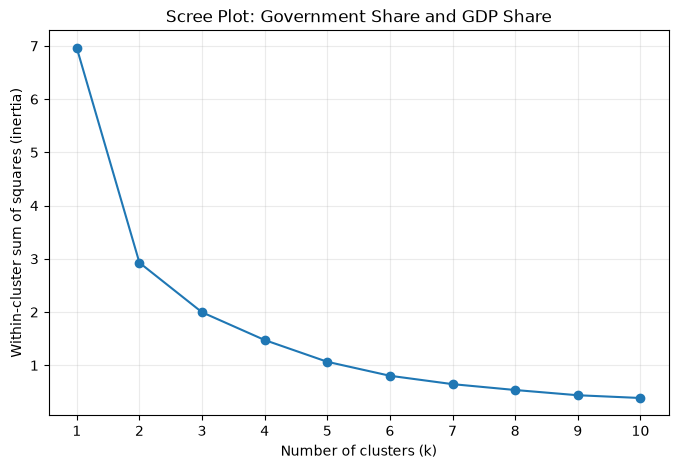

,k,Inertia
0,1,6.9609
1,2,2.9274
2,3,1.9958
3,4,1.4745
4,5,1.0657
5,6,0.8033
6,7,0.6460
7,8,0.5358
8,9,0.4375
9,10,0.3857



2020 Military Burden Clusters

Chosen k: 2

Cluster sizes:


,Number of countries
share_cluster,
0,35
1,113


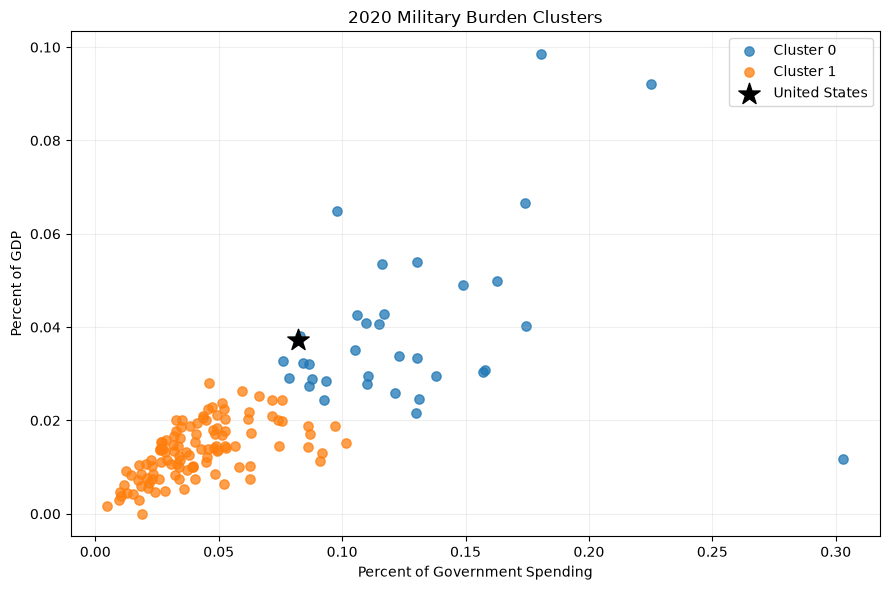


Descriptive statistics by cluster:


Percent of Government Spending                                \
                                       count      mean       std       min   
share_cluster                                                                
0                                       35.0  0.126456  0.046209  0.076005   
1                                      113.0  0.041394  0.020681  0.004896   

                                                      Percent of GDP  \
                    25%       50%       75%       max          count   
share_cluster                                                          
0              0.093093  0.116052  0.143584  0.303027           35.0   
1              0.026783  0.038486  0.051496  0.101501          113.0   

                                                                           \
                   mean       std       min       25%       50%       75%   
share_cluster                                                               
0              0.039433  0.018179  0.011742  0.028962  0.033281  0.042722   
1              0.013481  0.005966  0.000054  0.009147  0.013631  0.017830   

                         
                    max  
share_cluster            
0              0.098470  
1              0.028132


Cluster means:


,Percent of Government Spending,Percent of GDP
share_cluster,,
0,0.1265,0.0394
1,0.0414,0.0135



United States:


,Country,Percent of Government Spending,Percent of GDP,share_cluster
144,United States of America,0.081976,0.037179,0




Q2.4 — ALL FOUR VARIABLES

Normalized feature ranges:


,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
min,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0


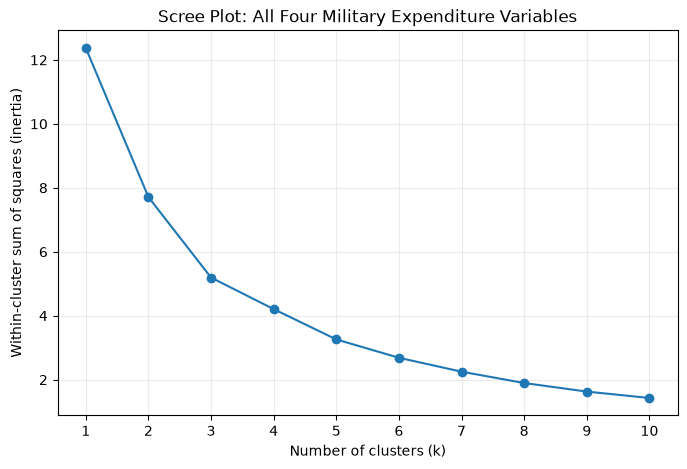

,k,Inertia
0,1,12.3724
1,2,7.7096
2,3,5.1926
3,4,4.2070
4,5,3.2582
5,6,2.6847
6,7,2.2500
7,8,1.8947
8,9,1.6273
9,10,1.4268



Cluster sizes:


,Number of countries
all_cluster,
0,31
1,6
2,111



All four variables — descriptive statistics:


Spending (2020 USD)                                             \
                          count           mean            std          min   
all_cluster                                                                  
0                          31.0    8786.086602   17901.909108   162.373364   
1                           6.0  147964.582042  309635.189564  6095.708713   
2                         111.0    7086.472777   26479.379918     8.622460   

                                                                     \
                     25%           50%           75%            max   
all_cluster                                                           
0             467.787851   1404.787234   7739.166193   72937.064048   
1            7700.424616  15897.570598  53872.942442  778397.200000   
2             130.010211    567.650747   3910.107493  257973.429834   

            Spending per Capita               ...  \
                          count         mean  ...   
all_cluster                                   ...   
0                          31.0   212.689100  ...   
1                           6.0  1875.150751  ...   
2                         111.0   196.926833  ...   

            Percent of Government Spending           Percent of GDP            \
                                       75%       max          count      mean   
all_cluster                                                                     
0                                 0.134663  0.303027           31.0  0.033492   
1                                 0.164503  0.225050            6.0  0.062634   
2                                 0.050505  0.092044          111.0  0.013419   

                                                                         
                  std       min       25%       50%       75%       max  
all_cluster                                                              
0            0.011449  0.011742  0.027560  0.032024  0.040531  0.066600  
1            0.028275  0.029429  0.041272  0.059257  0.085398  0.098470  
2            0.005996  0.000054  0.008873  0.013589  0.017769  0.028132  

[3 rows x 32 columns]


All four variables — cluster means:


,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
all_cluster,,,,
0,8786.0866,212.6891,0.1230,0.0335
1,147964.5820,1875.1508,0.1354,0.0626
2,7086.4728,196.9268,0.0404,0.0134


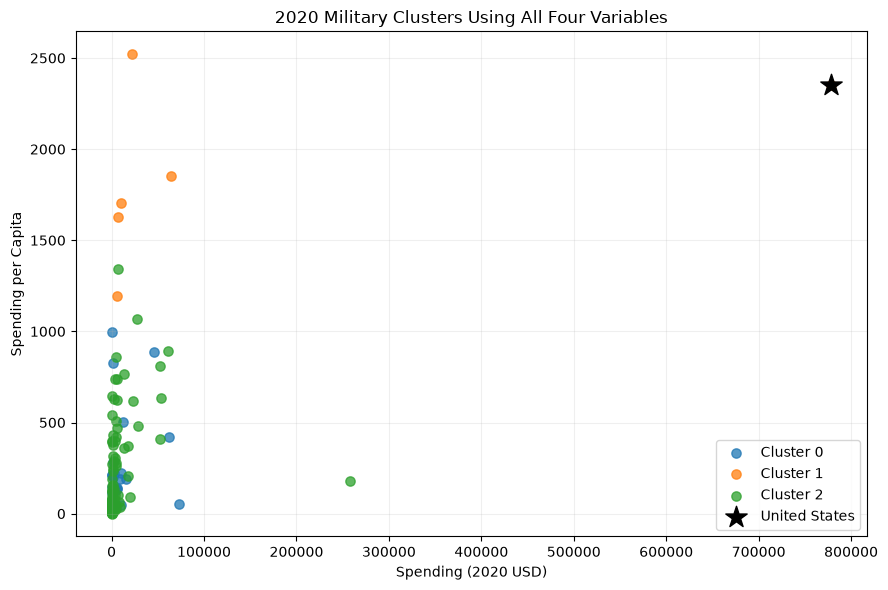


United States — all-variable cluster:


,Country,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP,all_cluster
144,United States of America,778397.2,2351.631858,0.081976,0.037179,1



Countries in each four-variable cluster:

Cluster 0: 31 countries
['India', 'Russia', 'Korea, South', 'Iran', 'Taiwan', 'Pakistan', 'Algeria', 'Colombia', 'Ukraine', 'Iraq', 'Morocco', 'Myanmar', 'Azerbaijan', 'Jordan', 'Lebanon']

Cluster 1: 6 countries
['United States of America', 'Saudi Arabia', 'Israel', 'Singapore', 'Kuwait', 'Oman']

Cluster 2: 111 countries
['China', 'United Kingdom', 'Germany', 'France', 'Japan', 'Italy', 'Australia', 'Canada', 'Brazil', 'Turkey', 'Spain', 'Poland', 'Netherlands', 'Indonesia', 'Mexico']


Q2.5 — COMPARISON

United States across all three analyses:


,Country,spend_cluster,share_cluster,all_cluster
144,United States of America,2,0,1



Cross-tabulation: Spending vs. Government/GDP shares


...


Cross-tabulation: Spending vs. All Four Variables


all_cluster,0,1,2
spend_cluster,,,
0,26,0,85
1,0,5,1
2,0,1,0
3,5,0,25



Cross-tabulation: Shares vs. All Four Variables


all_cluster,0,1,2
share_cluster,,,
0,29,6,0
1,2,0,111




FINAL VALIDATION
All Phase 2 Q2 validation checks passed.


In [15]:
# ============================================================
# PHASE 2 — REVISED Q2: SIPRI Military Expenditure Clustering
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

RANDOM_STATE = 42
N_INIT = 20

# ============================================================
# Q2.1 — Load, Filter, and Validate Data
# ============================================================

sipri = pd.read_csv(
    './data/SIPRI Military Expenditure Database.csv'
)

sipri_2020 = (
    sipri.loc[sipri['Year'] == 2020]
    .dropna()
    .reset_index(drop=True)
    .copy()
)

features = [
    'Spending (2020 USD)',
    'Spending per Capita',
    'Percent of Government Spending',
    'Percent of GDP'
]

print("Q2.1 — DATA VALIDATION")
print("=" * 50)

print("2020 complete observations:", len(sipri_2020))

assert len(sipri_2020) == 148, \
    "Expected 148 complete 2020 observations."

assert sipri_2020[features].notna().all().all(), \
    "Unexpected missing values."

assert all(
    pd.api.types.is_numeric_dtype(sipri_2020[col])
    for col in features
), "One or more features are not numeric."

print("\nFeature types:")
print(sipri_2020[features].dtypes)

print("\nFirst five countries:")
display(sipri_2020[['Country'] + features].head())

print("\nData validation passed.")


# ============================================================
# HELPER FUNCTIONS
# ============================================================

def minmax_frame(df):
    """
    Normalize each feature independently to [0, 1].
    """
    minimum = df.min()
    maximum = df.max()
    spread = maximum - minimum

    if (spread == 0).any():
        raise ValueError(
            "Cannot min-max normalize a constant feature."
        )

    normalized = (df - minimum) / spread

    assert normalized.notna().all().all()
    assert np.allclose(normalized.min().values, 0)
    assert np.allclose(normalized.max().values, 1)

    return normalized


def scree(X, title, max_k=10):
    """
    Calculate and plot K-means inertia for k=1,...,max_k.
    """
    k_values = range(1, max_k + 1)

    inertias = []

    for k in k_values:
        model = KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=N_INIT
        )

        model.fit(X)
        inertias.append(model.inertia_)

    plt.figure(figsize=(8, 5))

    plt.plot(
        list(k_values),
        inertias,
        marker='o'
    )

    plt.xlabel('Number of clusters (k)')
    plt.ylabel('Within-cluster sum of squares (inertia)')
    plt.title(title)
    plt.xticks(list(k_values))
    plt.grid(alpha=0.25)
    plt.show()

    inertia_table = pd.DataFrame({
        'k': list(k_values),
        'Inertia': inertias
    })

    display(inertia_table.round(4))

    return inertia_table


def fit_and_report(
    df,
    normalized_X,
    columns,
    k,
    cluster_column,
    title
):
    """
    Fit K-means, plot clusters in original units,
    and display descriptive statistics and U.S. placement.
    """

    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=N_INIT
    )

    df[cluster_column] = model.fit_predict(normalized_X)

    print("\n" + "=" * 60)
    print(title)
    print("=" * 60)

    print("\nChosen k:", k)

    print("\nCluster sizes:")
    display(
        df[cluster_column]
        .value_counts()
        .sort_index()
        .rename('Number of countries')
        .to_frame()
    )

    # Scatterplot in original units
    plt.figure(figsize=(9, 6))

    for cluster, group in df.groupby(cluster_column):
        plt.scatter(
            group[columns[0]],
            group[columns[1]],
            label=f'Cluster {cluster}',
            alpha=0.75,
            s=45
        )

    # Highlight the United States
    usa = df.loc[
        df['Country'] == 'United States of America'
    ]

    if not usa.empty:
        plt.scatter(
            usa[columns[0]],
            usa[columns[1]],
            marker='*',
            s=260,
            color='black',
            label='United States',
            zorder=5
        )

    plt.xlabel(columns[0])
    plt.ylabel(columns[1])
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

    # Required descriptive statistics
    print("\nDescriptive statistics by cluster:")

    display(
        df.groupby(cluster_column)[columns]
        .describe()
    )

    print("\nCluster means:")

    display(
        df.groupby(cluster_column)[columns]
        .mean()
        .round(4)
    )

    print("\nUnited States:")

    display(
        df.loc[
            df['Country'] == 'United States of America',
            ['Country'] + columns + [cluster_column]
        ]
    )

    return model


# ============================================================
# Q2.2 — Spending + Spending per Capita
# ============================================================

print("\n\nQ2.2 — SPENDING AND SPENDING PER CAPITA")
print("=" * 60)

spend_cols = [
    'Spending (2020 USD)',
    'Spending per Capita'
]

spend_norm = minmax_frame(
    sipri_2020[spend_cols]
)

print("\nNormalized feature ranges:")
display(
    spend_norm.agg(['min', 'max'])
)

spend_scree = scree(
    spend_norm,
    'Scree Plot: Spending and Spending per Capita'
)

# Defensible elbow choice
k_spend = 4

spend_model = fit_and_report(
    df=sipri_2020,
    normalized_X=spend_norm,
    columns=spend_cols,
    k=k_spend,
    cluster_column='spend_cluster',
    title='2020 Military Spending Clusters'
)


# ============================================================
# Q2.3 — Government Spending Share + GDP Share
# ============================================================

print("\n\nQ2.3 — MILITARY BURDEN")
print("=" * 60)

share_cols = [
    'Percent of Government Spending',
    'Percent of GDP'
]

share_norm = minmax_frame(
    sipri_2020[share_cols]
)

print("\nNormalized feature ranges:")
display(
    share_norm.agg(['min', 'max'])
)

share_scree = scree(
    share_norm,
    'Scree Plot: Government Share and GDP Share'
)

# Defensible elbow choice
k_share = 2

share_model = fit_and_report(
    df=sipri_2020,
    normalized_X=share_norm,
    columns=share_cols,
    k=k_share,
    cluster_column='share_cluster',
    title='2020 Military Burden Clusters'
)


# ============================================================
# Q2.4 — All Four Variables
# ============================================================

print("\n\nQ2.4 — ALL FOUR VARIABLES")
print("=" * 60)

all_cols = [
    'Spending (2020 USD)',
    'Spending per Capita',
    'Percent of Government Spending',
    'Percent of GDP'
]

all_norm = minmax_frame(
    sipri_2020[all_cols]
)

print("\nNormalized feature ranges:")
display(
    all_norm.agg(['min', 'max'])
)

all_scree = scree(
    all_norm,
    'Scree Plot: All Four Military Expenditure Variables'
)

# Defensible elbow choice
k_all = 3

all_model = KMeans(
    n_clusters=k_all,
    random_state=RANDOM_STATE,
    n_init=N_INIT
)

sipri_2020['all_cluster'] = all_model.fit_predict(
    all_norm
)

print("\nCluster sizes:")

display(
    sipri_2020['all_cluster']
    .value_counts()
    .sort_index()
    .rename('Number of countries')
    .to_frame()
)

print("\nAll four variables — descriptive statistics:")

display(
    sipri_2020
    .groupby('all_cluster')[all_cols]
    .describe()
)

print("\nAll four variables — cluster means:")

display(
    sipri_2020
    .groupby('all_cluster')[all_cols]
    .mean()
    .round(4)
)

# Scatterplot showing the all-variable cluster assignments
# using spending and spending per capita for visualization.

plt.figure(figsize=(9, 6))

for cluster, group in sipri_2020.groupby('all_cluster'):
    plt.scatter(
        group['Spending (2020 USD)'],
        group['Spending per Capita'],
        label=f'Cluster {cluster}',
        alpha=0.75,
        s=45
    )

usa = sipri_2020.loc[
    sipri_2020['Country'] == 'United States of America'
]

plt.scatter(
    usa['Spending (2020 USD)'],
    usa['Spending per Capita'],
    color='black',
    marker='*',
    s=260,
    label='United States',
    zorder=5
)

plt.xlabel('Spending (2020 USD)')
plt.ylabel('Spending per Capita')
plt.title('2020 Military Clusters Using All Four Variables')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("\nUnited States — all-variable cluster:")

display(
    sipri_2020.loc[
        sipri_2020['Country'] == 'United States of America',
        ['Country'] + all_cols + ['all_cluster']
    ]
)

print("\nCountries in each four-variable cluster:")

for cluster, group in sipri_2020.groupby('all_cluster'):

    print(f"\nCluster {cluster}: {len(group)} countries")

    print(
        group.sort_values(
            'Spending (2020 USD)',
            ascending=False
        )['Country']
        .head(15)
        .tolist()
    )


# ============================================================
# Q2.5 — Compare All Three Clustering Solutions
# ============================================================

print("\n\nQ2.5 — COMPARISON")
print("=" * 60)

print("\nUnited States across all three analyses:")

display(
    sipri_2020.loc[
        sipri_2020['Country'] == 'United States of America',
        [
            'Country',
            'spend_cluster',
            'share_cluster',
            'all_cluster'
        ]
    ]
)

print("\nCross-tabulation: Spending vs. Government/GDP shares")

display(
    pd.crosstab(
        sipri_2020['spend_cluster'],
        sipri_2020['share_cluster']
    )
)

print("\nCross-tabulation: Spending vs. All Four Variables")

display(
    pd.crosstab(
        sipri_2020['spend_cluster'],
        sipri_2020['all_cluster']
    )
)

print("\nCross-tabulation: Shares vs. All Four Variables")

display(
    pd.crosstab(
        sipri_2020['share_cluster'],
        sipri_2020['all_cluster']
    )
)


# ============================================================
# FINAL VERIFICATION
# ============================================================

print("\n\nFINAL VALIDATION")
print("=" * 60)

assert len(sipri_2020) == 148

assert sipri_2020[all_cols].notna().all().all()

assert sipri_2020['spend_cluster'].nunique() == 4

assert sipri_2020['share_cluster'].nunique() == 2

assert sipri_2020['all_cluster'].nunique() == 3

assert len(sipri_2020.loc[
    sipri_2020['Country'] == 'United States of America'
]) == 1

print("All Phase 2 Q2 validation checks passed.")

### Revised Q2 Interpretation

**Q2.1 — Data Preparation**

After filtering the SIPRI dataset to 2020 and removing missing observations, 148 countries remain. All four variables are numeric, so no additional recoding is necessary. I used min-max normalization to put the variables on a comparable scale before clustering.

**Q2.2 — Spending and Spending per Capita**

I selected k = 4 based on the scree plot. Most countries fall into a large low-spending cluster, while smaller groups have higher spending or spending per capita. The United States forms its own cluster because its military expenditure is substantially higher than that of other countries. Countries such as Saudi Arabia, Israel, Singapore, Norway, Kuwait, and Oman form a separate group with high spending per capita.

**Q2.3 — Percent of Government Spending and Percent of GDP**

I selected k = 2 because the largest initial reduction in inertia occurs between one and two clusters. This analysis measures military burden rather than total spending. The United States belongs to the higher-burden cluster but is no longer uniquely isolated. This demonstrates that countries with smaller military budgets can still devote a substantial percentage of their economic resources to defense.

**Q2.4 — All Four Variables**

I selected k = 3 when combining all four normalized variables. The resulting clusters contain 111, 31, and 6 countries. The United States joins the small six-country cluster alongside Saudi Arabia, Israel, Singapore, Kuwait, and Oman.

Compared with Q2.2, the United States is no longer isolated because the percentage variables also influence the clustering. The combined model captures both absolute spending and relative military burden.

**Q2.5 — Usefulness of K-Means**

K-means is useful for identifying patterns and differences in military spending across countries. It helps distinguish countries with high total spending from those with high spending per capita or high military burden.

However, the results depend on the choice of variables, scaling method, and number of clusters. Extreme observations can also influence cluster membership. I would therefore use K-means as an exploratory tool rather than treating the clusters as definitive categories.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

What I saw from the AI-assisted revision was that it really helped improve the clarity and the reliability of the clustering analysis. One of the biggest improvements was adding verification steps rather than simply audimatically trusting the results. For example, the revised code checks that the SIPRI dataset contains exactly 148 complete observations from 2020 and confirms that all four variables are properly normalized between 0 and 1. It also uses consistent K-means settings to make the results reproducible.

One limitation I noticed was that AI initially treated the number of clusters suggested by the elbow method as if there were always one correct answer. After examining I realized that selecting k can be subjective, especially when the curve does not have a clear elbow.

To verify the revised solution, I reran the notebook and examined the graphs and descriptive statistics. I also checked the United States' position across the three analyses. The final validation checks passed, confirming that the dataset and clustering outputs met the expected requirements.

One remaining concern is that K-means is sensitive to outliers and normalization. Different variables, scaling methods, or years could produce different clustering results. Overall, AI was most useful for improving verification and interpretation, but its suggestions still required independent evaluation.